# ECG exploratory data analysis

Load an unmodified MIT-BIH Arrhythmia Database signal and its `.atr` annotations. Dataset provenance and license: [DATA_NOTICE.md](../DATA_NOTICE.md). Record 100 is the example used in the starter notebook; set `record_id` to another ID from `data/RECORDS` to inspect it.

In [26]:
from collections.abc import Sequence
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import wfdb

project_root = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "pyproject.toml").exists() and (path / "data/RECORDS").exists()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Open the notebook inside the project folder.")

record_id = "100"
record_ids = (project_root / "data/RECORDS").read_text().splitlines()
if record_id not in record_ids:
    raise ValueError(f"Unknown record ID: {record_id}")
record_path = project_root / "data/raw/mitdb-1.0.0" / record_id
record = wfdb.rdrecord(str(record_path))
annotations = wfdb.rdann(str(record_path), "atr")

if not isinstance(record, wfdb.Record):
    raise TypeError("Expected a single-segment WFDB Record.")

print(f"Record: {record.record_name}")
print(f"Samples: {record.sig_len}, sampling rate: {record.fs} Hz")
print(f"Channels: {list(zip(record.sig_name, record.units))}")
print(f"Annotations: {len(annotations.sample)}")

Record: 100
Samples: 650000, sampling rate: 360 Hz
Channels: [('MLII', 'mV'), ('V5', 'mV')]
Annotations: 2274


In [27]:
from collections import Counter

Counter(annotations.symbol)

Counter({'N': 2239, 'A': 33, '+': 1, 'V': 1})

## Signal with annotations

The plot uses physical signal values and sample positions from the raw files. Every `.atr` annotation in the selected time interval is marked at its sample position and labeled with its original WFDB symbol. No annotation symbols are remapped or excluded. The displayed interval is half-open: `[start_s, start_s + duration_s)`.

Select a single channel with `channel=0` or both channels with `channel=(0, 1)`. Set `layout="overlay"` for one shared axis or `layout="stacked"` for separate rows with a shared time axis. Each channel's signal, annotation markers, and symbols share a color. Both examples below use the same 10-second interval.

In [28]:
def plot_ecg_with_annotations(
    record,
    annotations,
    channel: int | Sequence[int] = 0,
    start_s=0.0,
    duration_s=10.0,
    layout="overlay",
):
    """Plot one or two ECG channels with their original `.atr` annotation symbols.

    The displayed interval is [start_s, start_s + duration_s). Each annotation
    is placed at its sample position on every selected channel, with its symbol
    to the right of the marker. A channel's signal, annotation markers, and
    annotation symbols share the same color.

    Args:
        record: WFDB Record with loaded physical signal values.
        annotations: WFDB Annotation for the same record.
        channel: Zero-based channel index or a sequence of one or two unique
            indices, such as (0, 1). Defaults to 0.
        start_s: Interval start in seconds (default: 0).
        duration_s: Interval length in seconds (default: 10).
        layout: "overlay" draws selected channels on one axis; "stacked" draws
            one channel per row with a shared time axis. Defaults to "overlay".
            Overlay requires all selected channels to use the same unit.

    Returns:
        Tuple of a Matplotlib figure and either one Axes object or an array of
        Axes objects when multiple channels are stacked.
    """
    if record.record_name != annotations.record_name:
        raise ValueError("The signal and annotations must belong to the same record.")
    if annotations.fs is not None and annotations.fs != record.fs:
        raise ValueError("The signal and annotation sampling rates differ.")
    if isinstance(channel, (int, np.integer)):
        channels = [channel]
    else:
        try:
            channels = list(channel)
        except TypeError as exc:
            raise ValueError("Channel must be an index or a sequence of indices.") from exc
    if not 1 <= len(channels) <= 2 or any(
        not isinstance(index, (int, np.integer)) or not 0 <= index < record.n_sig
        for index in channels
    ):
        raise ValueError(f"Select one or two channel indices from 0 to {record.n_sig - 1}.")
    if len(set(channels)) != len(channels):
        raise ValueError("Channel indices must be unique.")
    if layout not in ("overlay", "stacked"):
        raise ValueError('Layout must be "overlay" or "stacked".')
    if layout == "overlay" and len({record.units[index] for index in channels}) != 1:
        raise ValueError("Overlay requires matching channel units; use the stacked layout.")
    if not np.isfinite(start_s) or not np.isfinite(duration_s) or start_s < 0 or duration_s <= 0:
        raise ValueError("Use a nonnegative start and a positive, finite duration.")

    first = round(start_s * record.fs)
    last = round((start_s + duration_s) * record.fs)
    if first >= last or last > record.sig_len:
        raise ValueError(f"The interval must contain samples within 0–{record.sig_len / record.fs:.2f} s.")

    sample_indices = np.arange(first, last)
    annotation_mask = (annotations.sample >= first) & (annotations.sample < last)
    annotation_samples = annotations.sample[annotation_mask]
    annotation_symbols = np.asarray(annotations.symbol)[annotation_mask]

    rows = len(channels) if layout == "stacked" else 1
    fig, axes = plt.subplots(nrows=rows, sharex=True, figsize=(14, 4 * rows))
    plot_axes = np.atleast_1d(axes)
    for position, index in enumerate(channels):
        ax = plot_axes[position if layout == "stacked" else 0]
        signal = record.p_signal[:, index]
        line, = ax.plot(
            sample_indices / record.fs, signal[first:last], linewidth=0.8,
            color=f"C{position}", label=record.sig_name[index],
        )
        ax.scatter(
            annotation_samples / record.fs, signal[annotation_samples],
            color=line.get_color(), s=24, zorder=3,
        )
        for sample, symbol in zip(annotation_samples, annotation_symbols):
            ax.annotate(
                symbol, (sample / record.fs, signal[sample]),
                xytext=(7, 0), textcoords="offset points",
                ha="left", va="center", color=line.get_color(), fontsize=8,
                bbox=dict(facecolor="white", edgecolor="none", pad=0.2),
            )

    for position, ax in enumerate(plot_axes):
        axis_channels = [channels[position]] if layout == "stacked" else channels
        names = ", ".join(record.sig_name[index] for index in axis_channels)
        ax.set(ylabel=f"Amplitude ({record.units[axis_channels[0]]})",
               title=f"Record {record.record_name}: {names}")
        ax.set_xlim(first / record.fs, last / record.fs)
        ax.margins(y=0.2)
        ax.grid(alpha=0.25)
        ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
    plot_axes[-1].set_xlabel("Time (s)")
    fig.tight_layout()
    return fig, axes

### Example 1: both channels on one axis

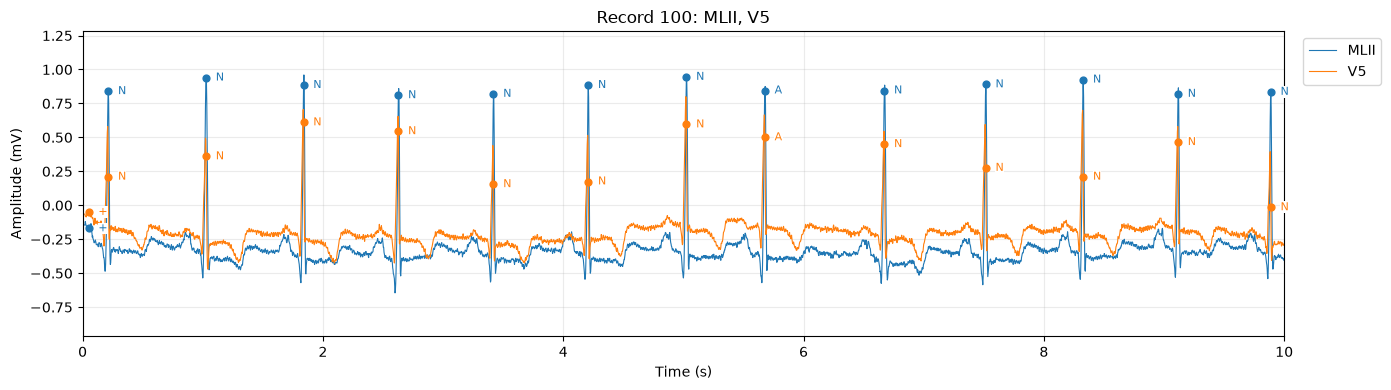

In [29]:
fig, ax = plot_ecg_with_annotations(
    record, annotations, channel=(0, 1), start_s=0, duration_s=10, layout="overlay"
)
plt.show()

### Example 2: one channel per row

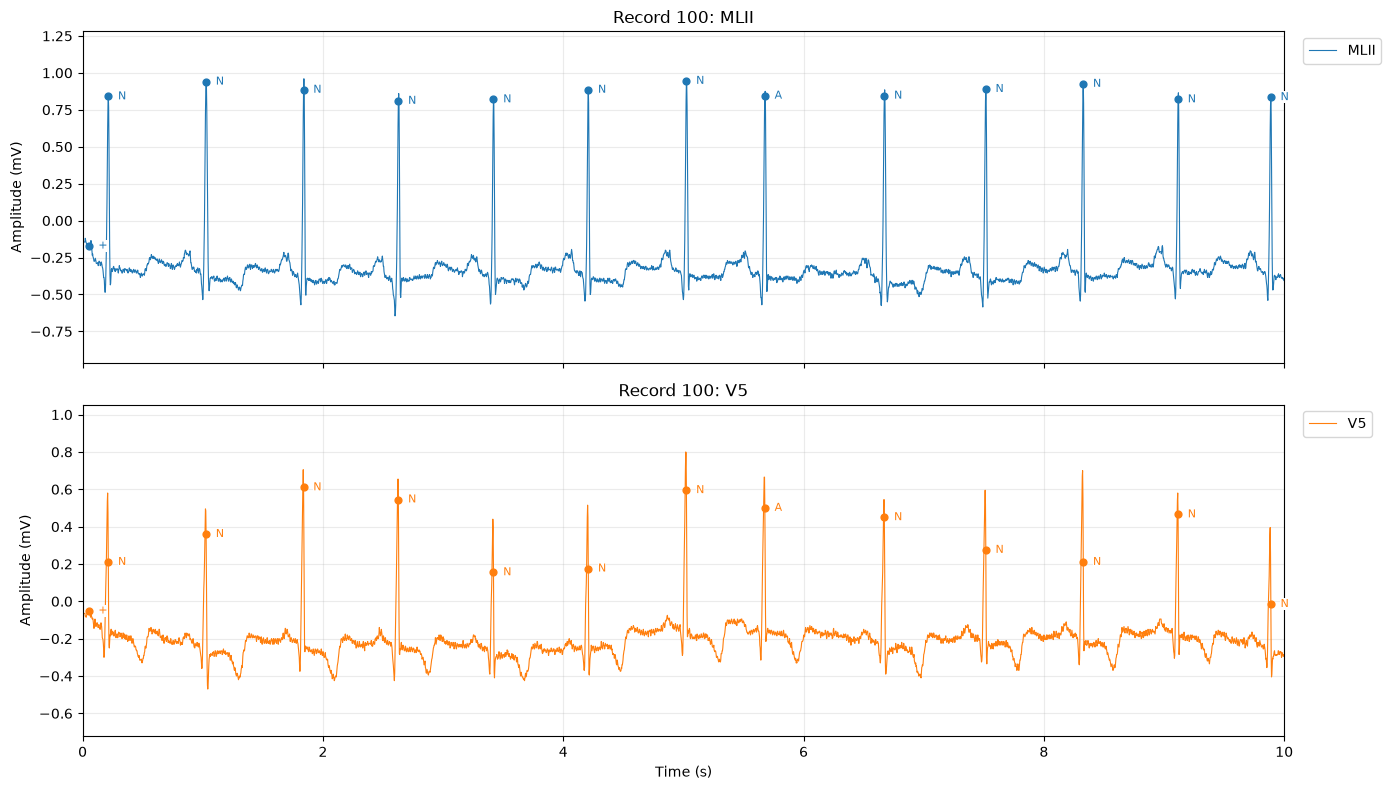

In [30]:
fig, axes = plot_ecg_with_annotations(
    record, annotations, channel=(0, 1), start_s=0, duration_s=10, layout="stacked"
)
plt.show()

## Annotation-centered windows

Each `ECGWindow` contains one selected channel from −0.5 s to +0.5 s, including both endpoints. At 360 Hz this gives 361 samples, with the central annotation at index 180. Missing samples are replaced by zeros; `left_padding` and `right_padding` record their counts, and `is_complete` is false if either count is nonzero.

`annotation` identifies the center. `other_annotations` contains every other `.atr` entry in the interval, including the same symbol, events such as `+`, and entries at either endpoint. Each entry retains its original annotation index, absolute sample, symbol, auxiliary note, and signed `offset_samples` from the center. Divide the offset by `fs` for seconds.

`extract_ecg_window` selects the center by its index in the annotation set. `generate_ecg_windows` yields windows lazily for an exact symbol (default `N`) and one channel (default `0`). Use full recordings and annotations with the same sample origin.

In [31]:
from collections.abc import Iterator
from dataclasses import dataclass, field

import numpy as np
import wfdb


@dataclass(frozen=True)
class WindowAnnotation:
    """An annotation located relative to a window's central annotation.

    Attributes:
        annotation_index: Index of this entry in the original annotation set.
        sample: Absolute sample index in the source record.
        symbol: Original WFDB annotation symbol.
        offset_samples: Signed sample offset from the central annotation.
        aux_note: Original auxiliary note, if available.
    """

    annotation_index: int
    sample: int
    symbol: str
    offset_samples: int
    aux_note: str | None = None


@dataclass
class ECGWindow:
    """One channel spanning 0.5 seconds on either side of an annotation.

    Both endpoints are included: at 360 Hz, signal has 361 samples and its
    central annotation is at index 180. Missing source samples are zeros.

    Attributes:
        signal: Independent 1D array of physical signal values, including padding.
        fs: Sampling rate in Hz.
        record_name: Identifier of the source recording.
        channel: Zero-based channel index in the source record.
        channel_name: Original channel name.
        unit: Physical unit of the signal values, for example mV.
        annotation: Central annotation; its offset_samples is always zero.
        other_annotations: All other entries in the inclusive window interval,
            including entries with the same symbol or at the same sample.
        left_padding: Number of missing samples replaced by zeros on the left.
        right_padding: Number of missing samples replaced by zeros on the right.
    """

    signal: np.ndarray = field(repr=False)
    fs: float
    record_name: str
    channel: int
    channel_name: str
    unit: str
    annotation: WindowAnnotation
    other_annotations: tuple[WindowAnnotation, ...]
    left_padding: int
    right_padding: int

    @property
    def center_index(self) -> int:
        """Return the central annotation's sample index within signal."""
        return self.signal.size // 2

    @property
    def is_complete(self) -> bool:
        """Return True if every sample comes from the source, without padding."""
        return self.left_padding == 0 and self.right_padding == 0

    @property
    def has_other_annotations(self) -> bool:
        """Return True if the window contains entries besides its central annotation."""
        return bool(self.other_annotations)

In [32]:
def extract_ecg_window(
    record: wfdb.Record,
    annotations: wfdb.Annotation,
    annotation_index: int,
    channel: int = 0,
) -> ECGWindow:
    """Extract a centered, single-channel window, padding missing samples with zeros.

    The inclusive interval is [annotation time - 0.5 s, annotation time + 0.5 s].
    The sampling rate must place both endpoints on integer sample indices.
    Annotation entries are distinguished by their original indices, so another
    entry at the central sample is retained among other_annotations.

    Args:
        record: WFDB Record with physical signals loaded from sample zero.
        annotations: WFDB Annotation using the same record and sample origin.
        annotation_index: Zero-based index of the central annotation entry,
            not its sample position in the recording.
        channel: Zero-based channel to extract (default: 0).

    Returns:
        ECGWindow with a signal copy, original annotation metadata, and padding
        counts. Its is_complete flag is False whenever padding was needed.
    """
    signal = record.p_signal
    samples = annotations.sample
    symbols = annotations.symbol
    names = record.sig_name
    units = record.units
    fs = record.fs
    if signal is None or samples is None or symbols is None:
        raise ValueError("Physical signal values, annotation samples, and symbols are required.")
    if names is None or units is None or record.record_name is None:
        raise ValueError("Record name, channel names, and physical units are required.")
    if record.record_name != annotations.record_name:
        raise ValueError("The signal and annotations must belong to the same record.")
    if fs is None or not np.isfinite(fs) or fs <= 0:
        raise ValueError("The record must have a positive, finite sampling rate.")
    if annotations.fs is not None and annotations.fs != fs:
        raise ValueError("The signal and annotation sampling rates differ.")
    half_width = float(fs) * 0.5
    if not half_width.is_integer():
        raise ValueError("The sampling rate must represent 0.5 seconds as an integer sample count.")
    if signal.ndim != 2 or signal.shape[0] == 0:
        raise ValueError("Physical signals must be a nonempty samples-by-channels array.")
    if not isinstance(channel, (int, np.integer)) or not 0 <= channel < signal.shape[1]:
        raise ValueError(f"Channel must be an integer from 0 to {signal.shape[1] - 1}.")
    if len(names) != signal.shape[1] or len(units) != signal.shape[1]:
        raise ValueError("Channel metadata must match the signal columns.")
    if samples.ndim != 1 or not np.issubdtype(samples.dtype, np.integer) or len(samples) != len(symbols):
        raise ValueError("Annotation samples must be a 1D integer array matching the symbols.")
    if np.any(samples < 0) or np.any(samples >= signal.shape[0]):
        raise ValueError("Annotation samples must lie within the source recording.")
    if not isinstance(annotation_index, (int, np.integer)) or not 0 <= annotation_index < len(samples):
        raise ValueError("Annotation index must identify an entry in the annotation set.")
    notes = annotations.aux_note
    if notes is not None and len(notes) != len(samples):
        raise ValueError("Auxiliary notes must match the annotation entries.")

    half_samples = int(half_width)
    center = int(samples[annotation_index])
    first = center - half_samples
    last = center + half_samples + 1
    left_padding = max(0, -first)
    right_padding = max(0, last - signal.shape[0])
    window_signal = np.zeros(2 * half_samples + 1, dtype=signal.dtype)
    window_signal[left_padding:window_signal.size - right_padding] = signal[
        max(0, first):min(signal.shape[0], last), channel
    ]

    inside = np.flatnonzero((samples >= first) & (samples < last))
    entries = tuple(
        WindowAnnotation(
            annotation_index=int(index),
            sample=int(samples[index]),
            symbol=symbols[index],
            offset_samples=int(samples[index]) - center,
            aux_note=notes[index] if notes is not None else None,
        )
        for index in inside
    )
    return ECGWindow(
        signal=window_signal,
        fs=float(fs),
        record_name=record.record_name,
        channel=int(channel),
        channel_name=names[channel],
        unit=units[channel],
        annotation=next(entry for entry in entries if entry.annotation_index == annotation_index),
        other_annotations=tuple(entry for entry in entries if entry.annotation_index != annotation_index),
        left_padding=left_padding,
        right_padding=right_padding,
    )

In [33]:
def generate_ecg_windows(
    record: wfdb.Record,
    annotations: wfdb.Annotation,
    annotation_symbol: str = "N",
    channel: int = 0,
) -> Iterator[ECGWindow]:
    """Yield one window per matching annotation, in the original annotation order.

    Windows are created lazily. Only the center is selected by symbol; all
    other annotation entries inside each window are preserved.

    Args:
        record: WFDB Record with physical signals loaded from sample zero.
        annotations: WFDB Annotation using the same record and sample origin.
        annotation_symbol: Exact WFDB symbol to use as a window center
            (default: "N"). No label mapping is applied.
        channel: Zero-based channel to extract for every window (default: 0).

    Yields:
        ECGWindow with both 0.5-second endpoints included, original metadata,
        and completeness and other-annotation flags.
    """
    if annotations.symbol is None:
        raise ValueError("Annotation symbols are required.")
    if not isinstance(annotation_symbol, str) or not annotation_symbol:
        raise ValueError("Select a nonempty annotation symbol.")
    for index, symbol in enumerate(annotations.symbol):
        if symbol == annotation_symbol:
            yield extract_ecg_window(record, annotations, annotation_index=index, channel=channel)

In [34]:
windows = list(generate_ecg_windows(record, annotations, channel=0))
print(f"N windows: {len(windows)}")
print(f"Complete: {sum(window.is_complete for window in windows)}")
print(f"Incomplete: {sum(not window.is_complete for window in windows)}")

first_window = windows[0]
print(f"Signal shape: {first_window.signal.shape}; center index: {first_window.center_index}")
print(f"Central annotation: {first_window.annotation}")
print(f"Complete: {first_window.is_complete}; "
      f"padding (left, right): {(first_window.left_padding, first_window.right_padding)}")
print(f"Other annotations present: {first_window.has_other_annotations}")
print(f"Other annotations: {first_window.other_annotations}")

N windows: 2239
Complete: 2237
Incomplete: 2
Signal shape: (361,); center index: 180
Central annotation: WindowAnnotation(annotation_index=1, sample=77, symbol='N', offset_samples=0, aux_note='')
Complete: False; padding (left, right): (103, 0)
Other annotations present: True
Other annotations: (WindowAnnotation(annotation_index=0, sample=18, symbol='+', offset_samples=-59, aux_note='(N\x00'),)


## Static window grid

`plot_ecg_windows_grid` plots exactly the list of windows supplied to it as one static Matplotlib figure. Select a manageable subset before calling it; the example below displays the first 20 `N` windows from record 100, channel 0, in four columns.

Time is relative to the central annotation at 0 seconds. All supplied windows share amplitude limits. Red markers identify central annotations; orange markers identify other annotations. Gray regions and `[padded]` titles identify zero padding.

In [35]:
from collections.abc import Sequence

from matplotlib.lines import Line2D
from matplotlib.patches import Patch


def plot_ecg_windows_grid(
    windows: Sequence[ECGWindow],
    ncols: int = 4,
):
    """Plot the supplied ECG windows as one static grid.

    Time is relative to each central annotation, marked in red at 0 s.
    Other annotations are orange, and symbols appear to the right of markers.
    Gray shading identifies zero padding. Amplitude limits are shared across
    the supplied windows, which must all use the same physical unit.

    Args:
        windows: Nonempty list or sequence of ECGWindow objects in display
            order. Every supplied window is plotted; pass a small selection,
            such as windows[:20], to keep the figure readable.
        ncols: Maximum number of grid columns (default: 4).

    Returns:
        Tuple containing a Matplotlib figure and a 2D array of axes. Unused
        panels in the last row are hidden. Call plt.show() to display it.
    """
    if not len(windows):
        raise ValueError("Provide at least one ECG window.")
    if not isinstance(ncols, int) or ncols <= 0:
        raise ValueError("Column count must be a positive integer.")
    if len({window.unit for window in windows}) != 1:
        raise ValueError("Windows must use the same physical unit for shared amplitude limits.")

    columns = min(ncols, len(windows))
    rows = (len(windows) + columns - 1) // columns
    amplitude_min = min(float(window.signal.min()) for window in windows)
    amplitude_max = max(float(window.signal.max()) for window in windows)
    margin = 0.08 * (amplitude_max - amplitude_min) or 0.1
    fig, axes = plt.subplots(
        rows, columns, squeeze=False, sharex=True, sharey=True,
        figsize=(4 * columns, 2.6 * rows),
    )
    for position, window in enumerate(windows):
        ax = axes.flat[position]
        time_s = (np.arange(window.signal.size) - window.center_index) / window.fs
        if window.left_padding:
            edge = time_s[window.left_padding] - 0.5 / window.fs
            ax.axvspan(time_s[0], edge, facecolor="0.9", zorder=0)
        if window.right_padding:
            edge = time_s[window.signal.size - window.right_padding] - 0.5 / window.fs
            ax.axvspan(edge, time_s[-1], facecolor="0.9", zorder=0)
        ax.plot(time_s, window.signal, color="tab:blue", linewidth=0.8)
        ax.axvline(0, color="0.6", linestyle="--", linewidth=0.6, zorder=0)
        for entry in (window.annotation, *window.other_annotations):
            index = window.center_index + entry.offset_samples
            color = "tab:red" if entry.annotation_index == window.annotation.annotation_index else "tab:orange"
            ax.scatter(time_s[index], window.signal[index], color=color, s=15, zorder=3)
            ax.annotate(
                entry.symbol, (time_s[index], window.signal[index]),
                xytext=(5, 0), textcoords="offset points", ha="left", va="center",
                color=color, fontsize=7,
                bbox=dict(facecolor="white", edgecolor="none", pad=0.2),
            )
        status = " [padded]" if not window.is_complete else ""
        ax.set_title(
            f"#{position + 1} | {window.record_name}:{window.channel_name} | "
            f"{window.annotation.symbol} @ {window.annotation.sample / window.fs:.3f}s{status}",
            fontsize=8,
        )
        ax.set_xlim(time_s[0], time_s[-1])
        ax.set_ylim(amplitude_min - margin, amplitude_max + margin)
        ax.set_xticks([-0.5, 0, 0.5])
        ax.set_xlabel("Time from center (s)", fontsize=8)
        if position % columns == 0:
            ax.set_ylabel(f"Amplitude ({window.unit})", fontsize=8)
        ax.tick_params(labelsize=7, labelbottom=True)
        ax.grid(alpha=0.2)
    for ax in list(axes.flat)[len(windows):]:
        ax.set_axis_off()
    fig.suptitle(f"ECG windows | {len(windows)} selected", fontsize=12)
    fig.legend(
        handles=[
            Line2D([], [], marker="o", linestyle="none", color="tab:red", label="Central annotation"),
            Line2D([], [], marker="o", linestyle="none", color="tab:orange", label="Other annotations"),
            Patch(facecolor="0.9", label="Zero padding"),
        ],
        loc="lower center", ncol=3, fontsize=9,
    )
    fig.tight_layout(rect=(0, 0.035, 1, 0.965))
    return fig, axes

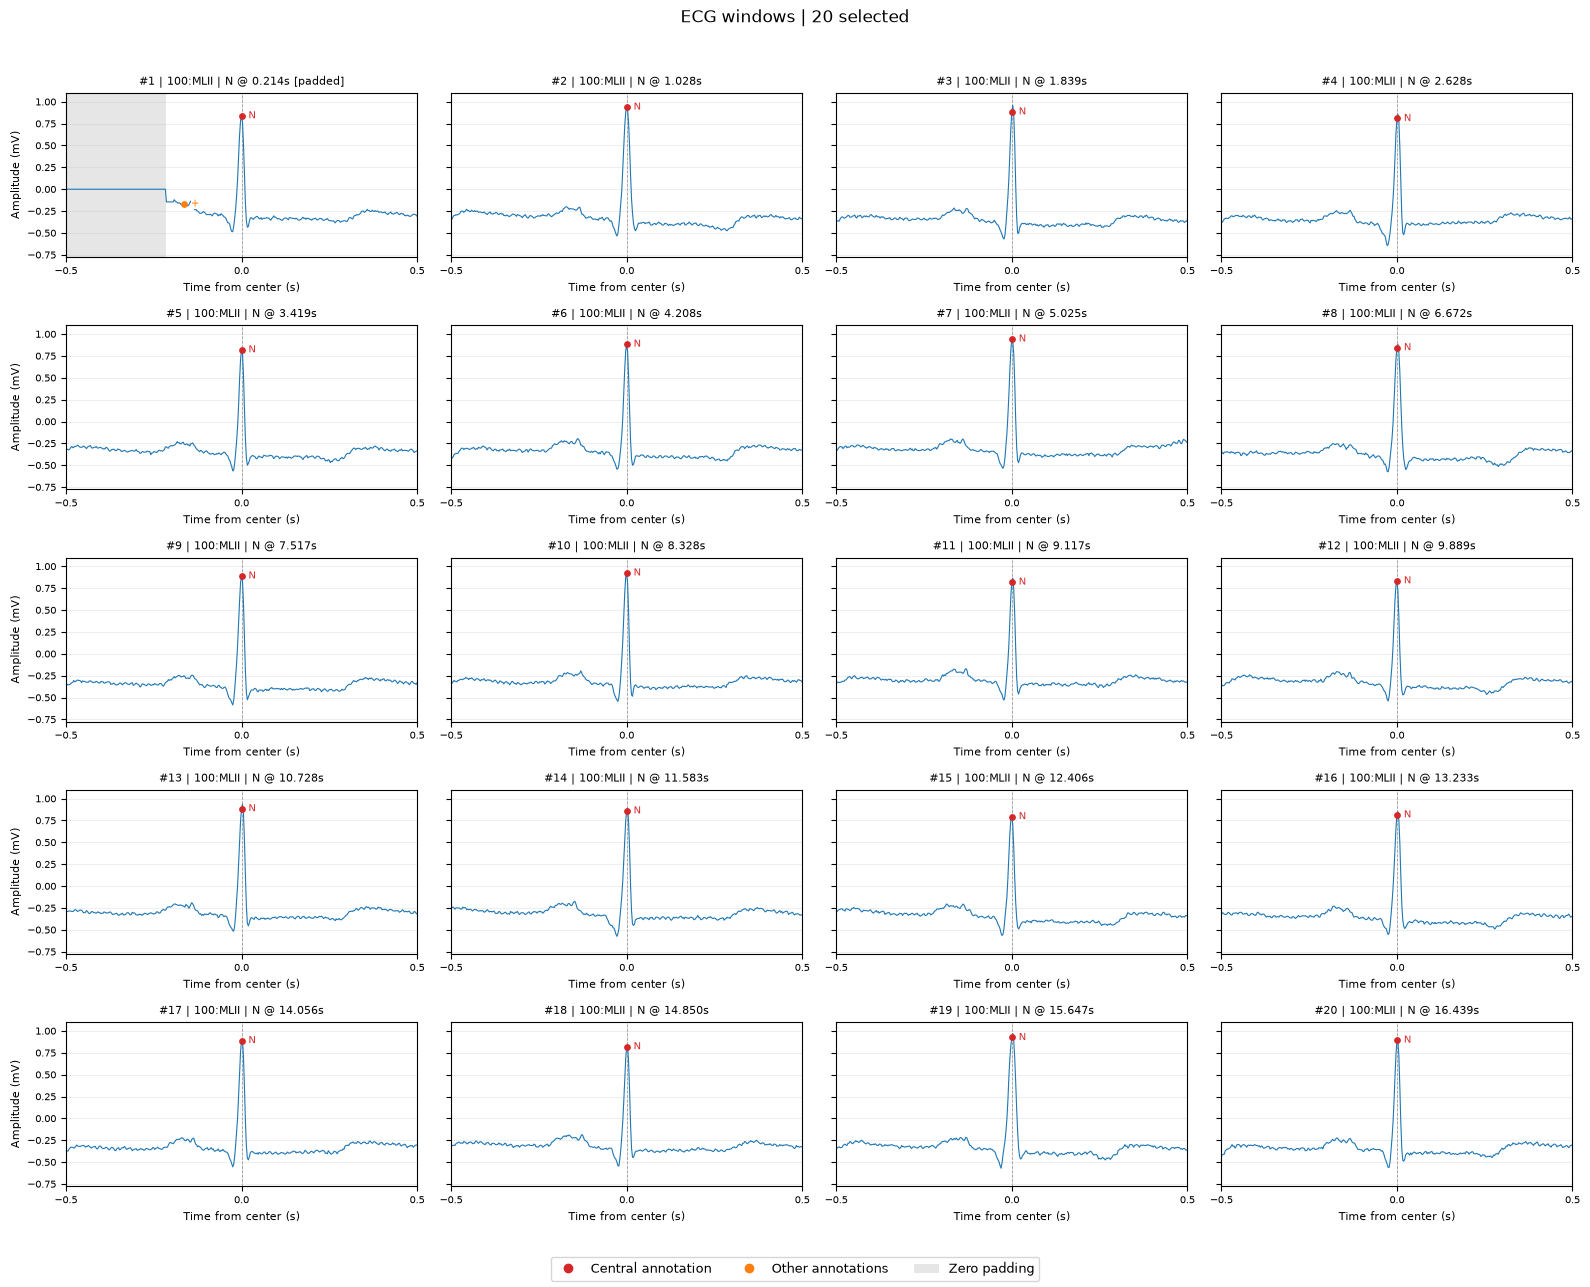

In [36]:
fig, axes = plot_ecg_windows_grid(windows[:20], ncols=4)
plt.show()